In [112]:
import pandas as pd
import matplotlib.pylab as plt
import seaborn as sns
import numpy as np

In [113]:
df = pd.read_csv('../csv/club_games.csv')
print(df.dtypes)
df

game_id                    int64
club_id                    int64
own_goals                  int64
own_position             float64
own_manager_name          object
opponent_id                int64
opponent_goals             int64
opponent_position        float64
opponent_manager_name     object
hosting                   object
is_win                     int64
dtype: object


,game_id,club_id,own_goals,own_position,own_manager_name,opponent_id,opponent_goals,opponent_position,opponent_manager_name,hosting,is_win
0,2221751,431,1,NaN,Lutz Göttling,60,2,NaN,Christian Streich,Home,0
1,2221755,83,3,NaN,Ralph Hasenhüttl,4795,0,NaN,Tomas Oral,Home,1
2,2222597,3725,2,2.0,Stanislav Cherchesov,232,1,5.0,Unai Emery,Home,1
3,2222627,2696,0,11.0,Andrey Kobelev,4128,2,10.0,Rustem Khuzin,Home,0
4,2222658,2410,0,2.0,Leonid Slutski,121,2,13.0,Dan Petrescu,Home,0
...,...,...,...,...,...,...,...,...,...,...,...
130427,4126931,20923,2,NaN,Sergey Perednya,12065,1,NaN,Aleksandr Gorbachev,Away,1
130428,4148237,920,0,NaN,Ruaidhri Higgins,10481,1,NaN,Milic Curcic,Away,0
130429,4171268,681,2,NaN,Imanol Alguacil,409,0,NaN,Gerhard Struber,Away,1
130430,4148252,144,3,NaN,Sergej Jakirovic,10532,1,NaN,Dan Brimsvík,Away,1


# Data Exploration
The dataset contains 11 columns and 130432 rows. The columns are:
- `game_id`: The unique identifier of the game
- `club_id`: The unique identifier of the club that played in home
- `own_goals`: The number of own goals scored by the home team
- `own_position`: The position of the home team in the league
- `own_manager_name`: The name of the manager of the home team
- `opponent_id`: The unique identifier of the club that played as visitor
- `opponent_goals`: The number of goals scored by the visitor team
- `opponent_position`: The position of the visitor team in the league
- `opponent_manager_name`: The name of the manager of the visitor team
- `hosting`: indicates if the home team is the hosting team or not
- `is_win`: indicates if the home team won the game or not
We are going also to change the data type of the columns `own_position` and `opponent_position` to integer.

## Data Cleaning

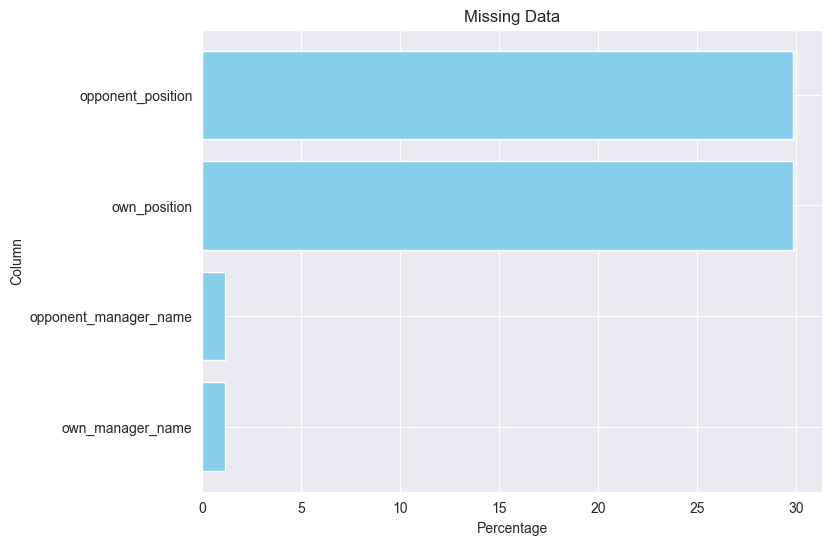

In [114]:
df['own_position'] = df['own_position'].astype('Int64')
df['opponent_position'] = df['opponent_position'].astype('Int64')

#check for duplicated rows
df.duplicated().sum()

#check for missing values
missing_values = df.isnull().mean() * 100
missing_values = missing_values[missing_values > 0].sort_values(ascending=True)  

# plt.figure -> Create a new figure with dimensions 8x6
plt.figure(figsize=(8, 6))
plt.barh(missing_values.index, missing_values.values, color='skyblue')  # Use barh for horizontal bars
plt.title('Missing Data')
plt.xlabel('Percentage')
plt.ylabel('Column')
plt.xticks(rotation=0)
plt.show()

## Visualization of the missing data
The dataset has no duplicated rows. There are missing values in the columns `opponent_position` , `own_position`, `opponent_manager_name` and `onw_manager_name`. We are going to modify the dataset only for the columns `opponent_manager_name` and `own_manager_name`.

In [115]:
df.loc[df['opponent_manager_name'].isnull(), 'opponent_manager_name'] = 'Unknown'
df.loc[df['own_manager_name'].isnull(), 'own_manager_name'] = 'Unknown'
df.query('opponent_manager_name == "Unknown" or own_manager_name == "Unknown"')

,game_id,club_id,own_goals,own_position,own_manager_name,opponent_id,opponent_goals,opponent_position,opponent_manager_name,hosting,is_win
265,2258371,17797,0,<NA>,Unknown,317,1,<NA>,Unknown,Home,0
325,2289248,3060,0,4,Unknown,2079,0,14,Unknown,Home,0
329,2289291,3060,0,4,Unknown,6676,2,2,Unknown,Home,0
599,2366500,20417,5,<NA>,Unknown,22235,0,<NA>,Unknown,Home,1
601,2366512,24391,0,<NA>,Unknown,369,5,<NA>,Unknown,Home,0
...,...,...,...,...,...,...,...,...,...,...,...
130057,4072488,36,3,3,Unknown,7775,0,19,Unknown,Away,1
130058,4072493,7775,0,19,Unknown,589,3,12,Unknown,Away,0
130095,4157243,5091,7,<NA>,Unknown,77305,0,<NA>,Unknown,Away,1
130193,4115648,5792,4,<NA>,Unknown,13457,0,<NA>,Unknown,Away,1


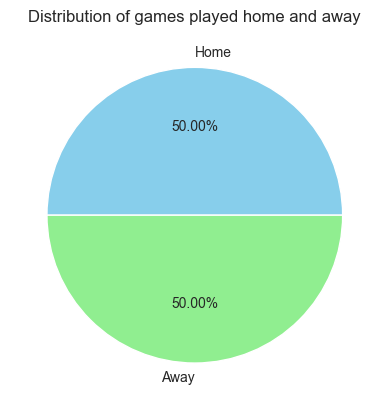

In [116]:
#plotting the number of games played home and away
games = df.groupby('hosting')
games_dim = games.size()

#creating a set of colors
color = ['#FABC2A', '#F05365']
plt.pie(games_dim, autopct='%.2f%%', colors=['skyblue', 'lightgreen'], labels=['Home', 'Away'])
plt.title('Distribution of games played home and away')
plt.show()

wins = games.agg(
    is_win= ('is_win', 'sum'),
    opponent_goals=('opponent_goals', 'sum'),
    home_goals=('own_goals', 'sum'),
)

bar_width = 0.35


## Distribution of games played home and away
The pie chart shows that the home team played 50.00% of the games at home and 50.00% of the games away, so we have a balanced dataset.

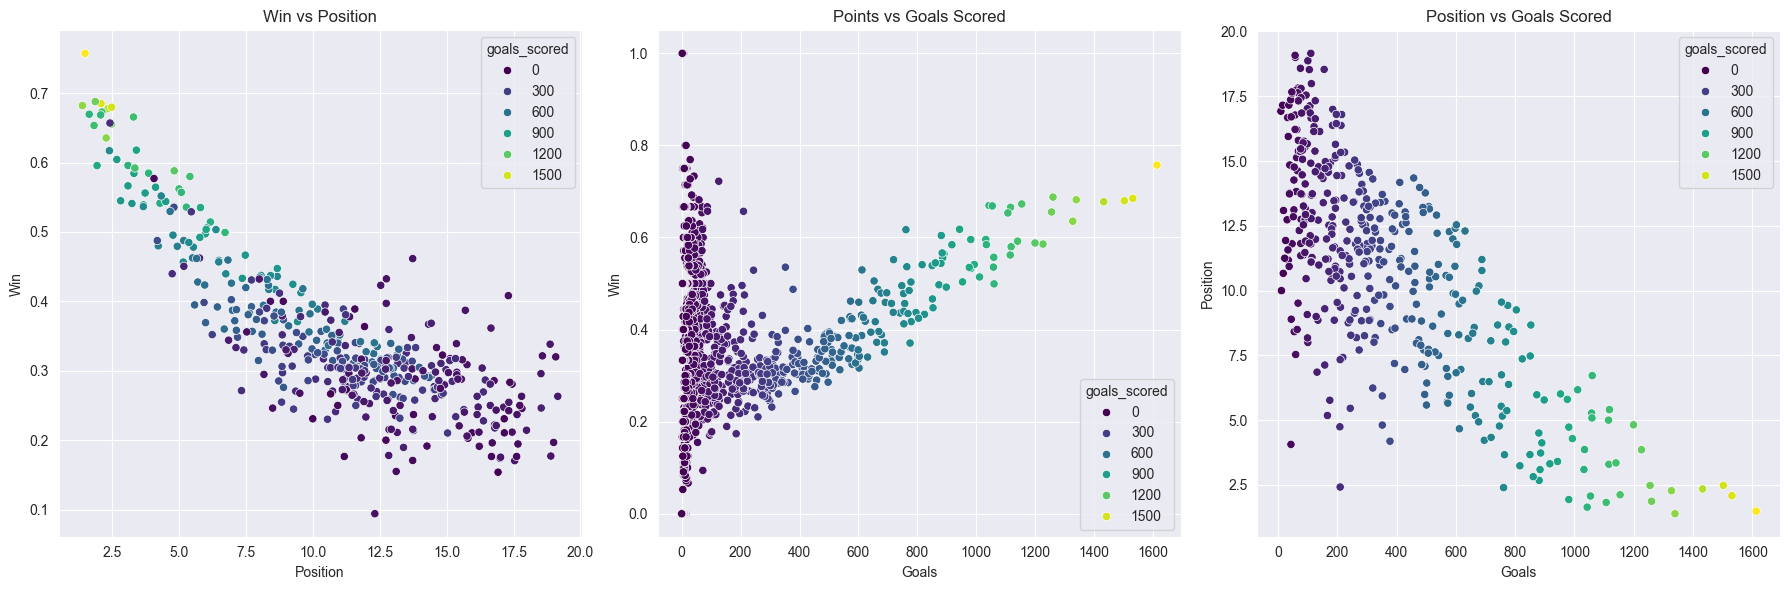

In [120]:
points = df.groupby('club_id').agg(
    is_win=('is_win', 'mean'),
    goals_scored=('own_goals', 'sum'),
    own_position=('own_position', 'mean'),
)

fig, ax = plt.subplots(1, 3, figsize=(18, 6))

# Scatter plot position vs points
sns.scatterplot(x='own_position', y='is_win', data=points, hue='goals_scored', palette='viridis', ax=ax[0])
ax[0].set_title('Win vs Position')
ax[0].set_xlabel('Position')
ax[0].set_ylabel('Win')

# Scatter plot goals scored vs points
sns.scatterplot(x='goals_scored', y='is_win', data=points, hue='goals_scored', palette='viridis', ax=ax[1])
ax[1].set_title('Points vs Goals Scored')
ax[1].set_xlabel('Goals')
ax[1].set_ylabel('Win')

# Scatter plot goals scored vs position
sns.scatterplot(x='goals_scored', y='own_position', data=points, hue='goals_scored', palette='viridis', ax=ax[2])
ax[2].set_title('Position vs Goals Scored')
ax[2].set_xlabel('Goals')
ax[2].set_ylabel('Position')


plt.tight_layout()
plt.show()

## Visual Analysis of Team Performance Metrics

The visualizations provide insights into the relationships between team performance metrics such as wins, goals scored, and league position.

### 1. Points vs Position
The scatter plot illustrates the relationship between a team's league position and its win percentage. Each point represents a club, with the color indicating the total goals scored. 

- **X-axis**: League Position (lower values indicate a better position)
- **Y-axis**: Win Percentage (mean of `is_win`, where 1 indicates a win)
- We can observe that teams with higher league positions tend to have higher win percentages.

### 2. Points vs Goals Scored
This scatter plot shows the relationship between the total goals scored by a team and its win percentage. 

- **X-axis**: Total Goals Scored
- **Y-axis**: Win Percentage (mean of `is_win`)
- The visualization suggests that teams with higher goals scored tend to have higher win percentages.

### 3. Position vs Goals Scored
In this plot, we examine the relationship between the total goals scored and the league position of the teams. 

- **X-axis**: Total Goals Scored
- **Y-axis**: League Position
- The visualization indicates that teams with higher goals scored tend to have better league positions.

These visualizations help us understand how a team's performance metrics are interrelated and provide insights into the factors influencing success in the league.
